# vLLM × OpenTelemetry — Request-Level p95/p99 Accuracy Lab

**Purpose:** Answer Sam's request with actual measurements from **Qwen3-0.6B on your Apple M4**, not simulated latency values. This notebook is **standalone**: it defines its own HTTP streaming client, OpenTelemetry tracing and histograms, comparisons, exports, and optional vLLM version inventory.

### Already running (do not restart)

| Service | Address | Why |
|---|---|---|
| vLLM | `http://127.0.0.1:8000` | inference and original server histograms |
| OTel scrape Collector | `127.0.0.1:8889` | existing Prometheus metrics pathway |
| Prometheus | `http://127.0.0.1:9090` | historical server metrics |
| Separate OTLP Collector | `127.0.0.1:14318` | push client spans and metric histograms to JSONL |
| Jupyter | current notebook | drives real inference requests |

**Run in order:** 1) preflight; 2) instrument; 3) warm up; 4) six-request pipeline test; 5) 100-request experiment; 6) quantile comparison; 7) optional extensions. Each inference-generating cell is clearly marked. Do **not** use *Run All*. The 500-request, overhead, and cleanup cells are opt-in.

**Science and scope:**
- Primary *like-for-like* accuracy comparison uses the **same successful client-observed E2E values**: raw empirical quantiles vs **actual OTel-exported coarse/fine histograms** (reconstructed raw histograms are labeled as a diagnostic fallback).
- vLLM `/metrics` is an **independent server-side** histogram. We capture before/after deltas, but **do not call its difference from client latency an estimation error**; transport and queue timing differ.
- Client TTFT = request send to first meaningful streamed content/reasoning. This is **not identical** to server TTFT. SSE frames are not necessarily one token; we do not claim true ITL.
- No prompts, model responses, or credentials are exported to tracing. Use only synthetic test prompts. Running tests generates real inference and may use substantial CPU/GPU time.
- With 100 requests, p99 is still inherently unstable; consider 500+ requests and repetitions before making general claims.

**Reference:** [Prometheus quantile interpolation](https://prometheus.io/docs/prometheus/latest/querying/functions/#histogram_quantile), [OpenTelemetry Python histogram views](https://opentelemetry-python.readthedocs.io/en/latest/sdk/metrics.view.html), [vLLM production metrics](https://docs.vllm.ai/en/latest/usage/metrics/).

## 1 — Configuration and package check

Run this first in the same notebook environment you used for your previous lab (`.venv-notebook`). It creates a **new results subfolder only**; no other existing files are deleted or overwritten.

In [1]:
import json, math, re, socket, sys, time, uuid, urllib.request, urllib.error
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE = "http://127.0.0.1:8000"
PROM = "http://127.0.0.1:9090"
OTLP = "http://127.0.0.1:14318"
MODEL = "Qwen/Qwen3-0.6B"
REQUEST_TIMEOUT_S = 120
MAX_TOKENS = 64
CONCURRENCY = 2
CHAT_TEMPLATE_KWARGS = {"enable_thinking": False}  # Set None if your vLLM build rejects this
ROOT = Path.cwd().resolve()
OUT = ROOT / "bench_results" / "sam_percentile_lab"
OUT.mkdir(parents=True, exist_ok=True)
RUNS = {}

# Seconds: coarse buckets vs finer buckets. Boundaries must be strictly increasing.
COARSE = [0.1, 0.25, 0.5, 1, 2, 3, 5, 7.5, 10, 15, 30, 60, 120]
FINE = [float(x) for x in np.geomspace(0.05, 120, 90)]

print("Notebook Python:", sys.executable)
print("Working directory:", ROOT)
print("Results:", OUT)
print("Primary comparison: one client-observed request population, raw vs OTel bucket estimates")

Notebook Python: /Users/shrutikulkarni/Pranav-vLLM-Lab/.venv-notebook/bin/python
Working directory: /Users/shrutikulkarni/Pranav-vLLM-Lab
Results: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/sam_percentile_lab
Primary comparison: one client-observed request population, raw vs OTel bucket estimates


## 2 — Service preflight (no inference)

This validates the running services. A socket-open test of the OTLP Collector only checks reachability; the six-request test later verifies **actual export**. If a service is down, fix its Terminal process before continuing.

In [2]:
def get_url_text(url, timeout=5):
    with urllib.request.urlopen(url, timeout=timeout) as r:
        return r.read().decode("utf-8", errors="replace")

checks = {}
for label, url in [
    ("vLLM /v1/models", BASE + "/v1/models"),
    ("vLLM /metrics", BASE + "/metrics"),
    ("Scrape Collector /metrics", "http://127.0.0.1:8889/metrics"),
    ("Prometheus readiness", PROM + "/-/ready"),
]:
    try:
        text = get_url_text(url)
        checks[label] = "OK" if text else "EMPTY"
    except Exception as exc:
        checks[label] = "ERROR " + str(exc)[:140]
try:
    with socket.create_connection(("127.0.0.1", 14318), timeout=3):
        checks["OTLP Collector :14318"] = "TCP reachable"
except OSError as exc:
    checks["OTLP Collector :14318"] = "ERROR " + str(exc)
display(pd.DataFrame([{"service": k, "status": v} for k, v in checks.items()]))

model_data = json.loads(get_url_text(BASE + "/v1/models"))
served_models = [m.get("id") for m in model_data.get("data", [])]
print("Served model IDs:", served_models)
assert MODEL in served_models, "Set MODEL in Section 1 to a served model ID"
assert all(v.startswith(("OK", "TCP")) for v in checks.values()), "Fix unhealthy services before inference"

,service,status
0,vLLM /v1/models,OK
1,vLLM /metrics,OK
2,Scrape Collector /metrics,OK
3,Prometheus readiness,OK
4,OTLP Collector :14318,TCP reachable


Served model IDs: ['Qwen/Qwen3-0.6B']


## 3 — Streaming request timer (client measurements)

This is intentionally independent of the previous notebook. It measures every **completed streaming HTTP request** using `perf_counter_ns` and stores a UTC timestamp for time-series analysis. It does not retain prompts or generated text.

In [3]:
PROMPT_TASK = (
    "Give a short practical explanation of one AI inference latency optimization "
    "with a simple example in two or three sentences."
)

def make_prompt(request_id):
    # Unique identifier near beginning limits unintentional prefix-cache reuse.
    return f"Benchmark ID {request_id}. {PROMPT_TASK}"

def request_once(request_id, max_tokens=MAX_TOKENS):
    payload = {
        "model": MODEL,
        "messages": [{"role": "user", "content": make_prompt(request_id)}],
        "temperature": 0.0,
        "max_tokens": max_tokens,
        "stream": True,
        "stream_options": {"include_usage": True},
    }
    if CHAT_TEMPLATE_KWARGS is not None:
        payload["chat_template_kwargs"] = CHAT_TEMPLATE_KWARGS
    req = urllib.request.Request(
        BASE + "/v1/chat/completions", data=json.dumps(payload).encode(),
        headers={"Content-Type": "application/json"}, method="POST"
    )
    start_wall_ns = time.time_ns()
    start = time.perf_counter_ns()
    first = None
    saw_done, output_tokens, prompt_tokens, finish = False, None, None, None
    status, error = "INCOMPLETE", ""
    try:
        with urllib.request.urlopen(req, timeout=REQUEST_TIMEOUT_S) as resp:
            for raw in resp:
                line = raw.decode("utf-8", errors="replace").strip()
                if not line.startswith("data:"):
                    continue
                message = line[5:].strip()
                if message == "[DONE]":
                    saw_done = True
                    break
                if not message:
                    continue
                event = json.loads(message)
                if event.get("error"):
                    raise RuntimeError(str(event["error"]))
                usage = event.get("usage") or {}
                output_tokens = usage.get("completion_tokens", output_tokens)
                prompt_tokens = usage.get("prompt_tokens", prompt_tokens)
                for choice in event.get("choices", []):
                    finish = choice.get("finish_reason") or finish
                    delta = choice.get("delta") or {}
                    meaningful = any(isinstance(delta.get(k), str) and delta[k]
                                     for k in ("content", "reasoning_content", "reasoning"))
                    if meaningful and first is None:
                        first = time.perf_counter_ns()
        status = "OK" if saw_done and first is not None else "INCOMPLETE"
    except Exception as exc:
        status, error = "ERROR", repr(exc)
    end = time.perf_counter_ns()
    end_wall_ns = time.time_ns()
    e2e = (end - start) / 1e9
    ttft = ((first - start) / 1e9) if first is not None else math.nan
    return {
        "request_id": str(request_id),
        "start_utc_ns": start_wall_ns,
        "end_utc_ns": end_wall_ns,
        "end_utc": datetime.fromtimestamp(end_wall_ns/1e9, timezone.utc).isoformat(),
        "status": status,
        "e2e_s": e2e,
        "ttft_s": ttft,
        "prompt_tokens": prompt_tokens,
        "output_tokens": output_tokens,
        "finish_reason": finish,
        "error": error,
    }

## 4 — Initialize the OTel SDK (once per kernel)

Your **existing second Collector** receives OTLP/HTTP on `:14318`. These SDK histograms have two explicit bucket layouts. Each completed request also creates an individual span with E2E and TTFT attributes; **the exported spans preserve per-request measurements even though the OTel histograms do not**. Do not rerun this cell repeatedly without restarting the notebook kernel.

In [4]:
from opentelemetry.sdk.resources import Resource
from opentelemetry.sdk.trace import TracerProvider
from opentelemetry.sdk.trace.export import BatchSpanProcessor
from opentelemetry.sdk.metrics import MeterProvider
from opentelemetry.sdk.metrics.export import PeriodicExportingMetricReader
from opentelemetry.sdk.metrics.view import View, ExplicitBucketHistogramAggregation
from opentelemetry.exporter.otlp.proto.http.trace_exporter import OTLPSpanExporter
from opentelemetry.exporter.otlp.proto.http.metric_exporter import OTLPMetricExporter

assert "LAB_TRACE_PROVIDER" not in globals(), "OTel already initialized. Reuse the existing providers or restart the kernel."
resource = Resource.create({"service.name": "pranav-vllm-percentile-client", "lab.environment": "local-m4"})
LAB_TRACE_PROVIDER = TracerProvider(resource=resource)
LAB_TRACE_PROVIDER.add_span_processor(BatchSpanProcessor(
    OTLPSpanExporter(endpoint=OTLP + "/v1/traces", timeout=15),
    schedule_delay_millis=200, max_export_batch_size=64))
TRACER = LAB_TRACE_PROVIDER.get_tracer("pranav-percentiles")

reader = PeriodicExportingMetricReader(
    OTLPMetricExporter(endpoint=OTLP + "/v1/metrics", timeout=15),
    export_interval_millis=30000)
LAB_METER_PROVIDER = MeterProvider(
    resource=resource, metric_readers=[reader],
    views=[
        View(instrument_name="lab.client.e2e.coarse", aggregation=ExplicitBucketHistogramAggregation(boundaries=COARSE)),
        View(instrument_name="lab.client.e2e.fine", aggregation=ExplicitBucketHistogramAggregation(boundaries=FINE)),
    ])
meter = LAB_METER_PROVIDER.get_meter("pranav-percentiles")
HIST_COARSE = meter.create_histogram("lab.client.e2e.coarse", unit="s")
HIST_FINE = meter.create_histogram("lab.client.e2e.fine", unit="s")
METRIC_PATH = ROOT / "bench_results" / "otlp_client_metrics.jsonl"
TRACE_PATH = ROOT / "bench_results" / "otlp_client_traces.jsonl"
print("OTLP tracing + coarse/fine histograms configured; files:")
print(TRACE_PATH, METRIC_PATH, sep="\n")

OTLP tracing + coarse/fine histograms configured; files:
/Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/otlp_client_traces.jsonl
/Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/otlp_client_metrics.jsonl


## 5 — Warm up first (2 real requests)

Warming up avoids treating initial model startup/caching behavior as ordinary latency. The initial two calls are *excluded* from all later percentile calculations.

In [5]:
warm = [request_once("warmup-" + uuid.uuid4().hex[:8]) for _ in range(2)]
display(pd.DataFrame(warm)[["status", "e2e_s", "ttft_s", "output_tokens", "error"]])
assert all(x["status"] == "OK" for x in warm), "Fix request errors before continuing"

,status,e2e_s,ttft_s,output_tokens,error
0,OK,3.104125,1.862727,64,
1,OK,1.461687,0.123157,64,


## 6 — Experiment functions: direct vLLM snapshots + OTLP per-request export

The server histogram snapshot is read **immediately before and after** the controlled workload. This is only a contextual comparison because client E2E and server E2E have different definitions. Avoid any other client traffic while running a test.

In [6]:
SERVER_HISTOGRAM = "vllm:e2e_request_latency_seconds_bucket"

def server_hist_snapshot():
    """Aggregate the server's classic histogram buckets across matching series."""
    content = get_url_text(BASE + "/metrics", timeout=12)
    result = {}
    for line in content.splitlines():
        if not line.startswith(SERVER_HISTOGRAM + "{"):
            continue
        labelset, _, val = line.partition("} ")
        if not val:
            continue
        match = re.search(r'le="([^"]+)"', labelset)
        if not match:
            continue
        boundary = float(match.group(1))
        result[boundary] = result.get(boundary, 0.0) + float(val.split()[0])
    return result

def instrumented_one(run_id, seq, tracing=True):
    request_id = f"{run_id}-{seq}-{uuid.uuid4().hex[:8]}"
    if tracing:
        with TRACER.start_as_current_span("vllm.client.request") as span:
            row = request_once(request_id)
            span.set_attribute("lab.run_id", run_id)
            span.set_attribute("lab.request_id", request_id)
            span.set_attribute("lab.status", row["status"])
            span.set_attribute("lab.e2e_s", float(row["e2e_s"]))
            if math.isfinite(row["ttft_s"]):
                span.set_attribute("lab.ttft_s", float(row["ttft_s"]))
    else:
        row = request_once(request_id)
    row["run_id"] = run_id
    if tracing and row["status"] == "OK":
        attributes = {"run_id": run_id, "model": MODEL}
        HIST_COARSE.record(float(row["e2e_s"]), attributes)
        HIST_FINE.record(float(row["e2e_s"]), attributes)
    return row

def run_experiment(count, label, tracing=True, concurrency=CONCURRENCY, batch_size=20):
    assert 1 <= count <= 1000 and 1 <= concurrency <= 3 and 1 <= batch_size <= 50
    run_id = f"{label}-{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S')}-{uuid.uuid4().hex[:6]}"
    before = server_hist_snapshot()
    t0 = time.perf_counter()
    all_rows = []
    for low in range(0, count, batch_size):
        upper = min(count, low + batch_size)
        with ThreadPoolExecutor(max_workers=concurrency) as pool:
            future_map = [pool.submit(instrumented_one, run_id, n, tracing) for n in range(low, upper)]
            all_rows.extend([f.result() for f in as_completed(future_map)])
        print(f"{label}: finished {upper}/{count} requests")
    elapsed = time.perf_counter() - t0
    after = server_hist_snapshot()
    if tracing:
        ok_traces = LAB_TRACE_PROVIDER.force_flush(timeout_millis=20000)
        ok_metrics = LAB_METER_PROVIDER.force_flush(timeout_millis=20000)
        print("OTLP flush: traces", ok_traces, "metrics", ok_metrics)
    df = pd.DataFrame(all_rows).sort_values("start_utc_ns").reset_index(drop=True)
    df.to_csv(OUT / f"{run_id}_observations.csv", index=False)
    (OUT / f"{run_id}_server_hist_snapshots.json").write_text(json.dumps({
        "before": {str(k):v for k,v in before.items()},
        "after": {str(k):v for k,v in after.items()},
        "metric_name": SERVER_HISTOGRAM,
        "client_server_durations_comparable": False}, indent=2))
    RUNS[run_id] = {"df":df, "before":before, "after":after, "elapsed_s": elapsed, "tracing": tracing, "label":label}
    print("Run ID:", run_id, " | successes:", int((df.status == "OK").sum()), "/",count)
    print("Saved:", OUT / f"{run_id}_observations.csv")
    if (df.status != "OK").any():
        display(df.loc[df.status != "OK", ["request_id","status","error"]].head(10))
    return run_id

## 7 — Six-request pipeline test (real inference)

Runs only six requests and exports OTLP. Inspect both file sizes afterward. This is **pipeline QA only**, not a statistically meaningful p99 benchmark.

In [7]:
PILOT_ID = run_experiment(6, "pilot", batch_size=6)
display(RUNS[PILOT_ID]["df"][["status","e2e_s","ttft_s","output_tokens"]].round(4))
for path in (TRACE_PATH, METRIC_PATH):
    print(path.name, "exists:", path.exists(), "bytes:", path.stat().st_size if path.exists() else 0)

pilot: finished 6/6 requests
OTLP flush: traces True metrics True
Run ID: pilot-20261027T152214-78d9ee  | successes: 6 / 6
Saved: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/sam_percentile_lab/pilot-20261027T152214-78d9ee_observations.csv


,status,e2e_s,ttft_s,output_tokens
0,OK,1.9324,0.5057,64
1,OK,1.9380,0.5158,64
2,OK,1.2530,0.1747,48
3,OK,1.6339,0.1846,61
4,OK,1.0456,0.1480,38
5,OK,0.9637,0.1401,38


otlp_client_traces.jsonl exists: True bytes: 34357
otlp_client_metrics.jsonl exists: True bytes: 822480


## 8 — Quantile math + read the **actual OTel-exported histogram data**

Raw percentiles are calculated directly from individual successful requests (`numpy.percentile`, linear interpolation). The OTel Collector's JSONL file contains `resourceMetrics → scopeMetrics → metrics → histogram → dataPoints`, with **non-cumulative** bucket counts. We select the latest data point for the specific `run_id` (the SDK may have exported intermediate cumulative snapshots during a long run). If no matching exported histogram is found, the analysis **explicitly labels the fallback** and reconstructs histogram counts from the exact same raw latencies for a diagnostic estimate.

Our interpolation function models **Prometheus classic-histogram** quantile behavior: linear interpolation within each finite bucket, 0 as the lower bound of the first positive bucket, and the last finite bound returned if the quantile falls in the +Inf bucket.

In [8]:
def attributes_dict(attrs):
    def unpack(x):
        for field in ("stringValue","intValue","doubleValue","boolValue"):
            if field in x:
                return x[field]
        return None
    return {a["key"]: unpack(a.get("value", {})) for a in (attrs or [])}

def exported_histogram(run_id, name):
    if not METRIC_PATH.exists():
        return None
    candidates = []
    for raw_line in METRIC_PATH.open(encoding="utf-8"):
        try:
            envelope = json.loads(raw_line)
        except json.JSONDecodeError:
            continue
        for rm in envelope.get("resourceMetrics", []):
            for sm in rm.get("scopeMetrics", []):
                for m in sm.get("metrics", []):
                    if m.get("name") != name:
                        continue
                    for point in (m.get("histogram") or {}).get("dataPoints", []):
                        if attributes_dict(point.get("attributes", [])).get("run_id") != run_id:
                            continue
                        bounds = [float(x) for x in point.get("explicitBounds", [])]
                        counts = [float(x) for x in point.get("bucketCounts", [])]
                        if len(counts) != len(bounds) + 1:
                            continue
                        candidates.append((int(point.get("timeUnixNano", 0)), bounds, counts))
    if not candidates:
        return None
    _, bounds, counts = max(candidates, key=lambda x:x[0])
    return bounds, np.cumsum(np.array(counts, dtype=float)).tolist()

def reconstructed_histogram(values, bounds):
    cumulative = [int(np.count_nonzero(values <= x)) for x in bounds]
    return list(bounds), cumulative + [int(len(values))]

def classic_histogram_quantile(q, bounds, cumulative):
    bounds = list(map(float, bounds)) + [math.inf] if len(bounds) + 1 == len(cumulative) else list(map(float,bounds))
    if len(bounds) != len(cumulative) or not cumulative or cumulative[-1] <= 0:
        return math.nan
    target = q * cumulative[-1]
    previous_upper, previous_count = 0.0, 0.0
    for upper, current_count in zip(bounds, cumulative):
        if current_count >= target:
            if math.isinf(upper):
                return previous_upper  # Prometheus: highest finite bucket
            if current_count == previous_count:
                return upper
            return previous_upper + (upper - previous_upper) * ((target - previous_count) / (current_count - previous_count))
        previous_upper, previous_count = upper, current_count
    return math.nan

def compare_run(run_id):
    df = RUNS[run_id]["df"]
    vals = df.loc[(df.status == "OK") & np.isfinite(df.e2e_s), "e2e_s"].to_numpy(float)
    if len(vals) == 0:
        raise ValueError("No successful observations")
    rows = []
    for histogram_name, default_bounds, layout in [
        ("lab.client.e2e.coarse", COARSE, "coarse"),
        ("lab.client.e2e.fine", FINE, "fine")
    ]:
        actual = exported_histogram(run_id, histogram_name)
        if actual is not None and round(actual[1][-1]) == len(vals):
            bounds, cumul = actual
            source = "OTLP-exported histogram"
        else:
            bounds, cumul = reconstructed_histogram(vals, default_bounds)
            source = "reconstructed fallback (not verified OTLP)"
        for q in (0.50,0.95,0.99):
            exact = float(np.percentile(vals, q*100, method="linear"))
            estimated = classic_histogram_quantile(q, bounds, cumul)
            rows.append({"run_id":run_id, "layout":layout, "quantile":f"p{int(q*100)}",
                         "n":len(vals), "raw_s":exact, "estimated_s":estimated,
                         "abs_error_ms":abs(estimated-exact)*1000,
                         "signed_error_ms":(estimated-exact)*1000,
                         "bucket_count":len(bounds), "source":source})
    summary = pd.DataFrame(rows)
    summary.to_csv(OUT / f"{run_id}_percentile_comparison.csv", index=False)
    display(summary[["layout","quantile","n","raw_s","estimated_s","abs_error_ms","bucket_count","source"]].round(4))
    if any("fallback" in x for x in summary.source):
        print("WARNING: Collector-exported histogram unavailable/mismatched; above bucket estimates are diagnostic fallback only.")
    return summary

## 9 — Validate the pipeline's six-request histograms

Do not draw conclusions about accuracy from six observations. Confirm that **`source` equals `OTLP-exported histogram`** for both layouts. If not, investigate your Collector `file/client_metrics` output before running the 100-request test.

In [9]:
PILOT_COMPARISON = compare_run(PILOT_ID)

,layout,quantile,n,raw_s,estimated_s,abs_error_ms,bucket_count,source
0,coarse,p50,6,1.4435,1.4000,43.4823,13,OTLP-exported histogram
1,coarse,p95,6,1.9366,1.9400,3.4191,13,OTLP-exported histogram
2,coarse,p99,6,1.9377,1.9880,50.3073,13,OTLP-exported histogram
3,fine,p50,6,1.4435,1.2712,172.2458,90,OTLP-exported histogram
4,fine,p95,6,1.9366,1.9437,7.1509,90,OTLP-exported histogram
5,fine,p99,6,1.9377,1.9635,25.8191,90,OTLP-exported histogram


## 10 — Controlled 100-request experiment (real inference)

**This cell sends 100 requests with concurrency 2, in batches of 20.** vLLM server settings remain unchanged. Do not run another workload in parallel. This is the first usable accuracy comparison (p99 remains noisy at this sample size).

In [10]:
MAIN_ID = run_experiment(100, "main100", concurrency=2, batch_size=20)
MAIN_COMPARISON = compare_run(MAIN_ID)

main100: finished 20/100 requests
main100: finished 40/100 requests
main100: finished 60/100 requests
main100: finished 80/100 requests
main100: finished 100/100 requests
OTLP flush: traces True metrics True
Run ID: main100-20261027T152614-70adbd  | successes: 100 / 100
Saved: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/sam_percentile_lab/main100-20261027T152614-70adbd_observations.csv


,layout,quantile,n,raw_s,estimated_s,abs_error_ms,bucket_count,source
0,coarse,p50,100,1.6145,1.4731,141.4187,13,OTLP-exported histogram
1,coarse,p95,100,1.7336,1.9570,223.3431,13,OTLP-exported histogram
2,coarse,p99,100,1.9414,2.0000,58.6498,13,OTLP-exported histogram
3,fine,p50,100,1.6145,1.5652,49.3434,90,OTLP-exported histogram
4,fine,p95,100,1.7336,1.7910,57.3918,90,OTLP-exported histogram
5,fine,p99,100,1.9414,1.9685,27.1065,90,OTLP-exported histogram


## 11 — Visualize the raw latency distribution

The scatter plot represents **individual retained client request measurements**. Horizontal percentile lines are based on that same population. The histogram approximation is taken from OTLP only if the source check in Section 10 succeeded.

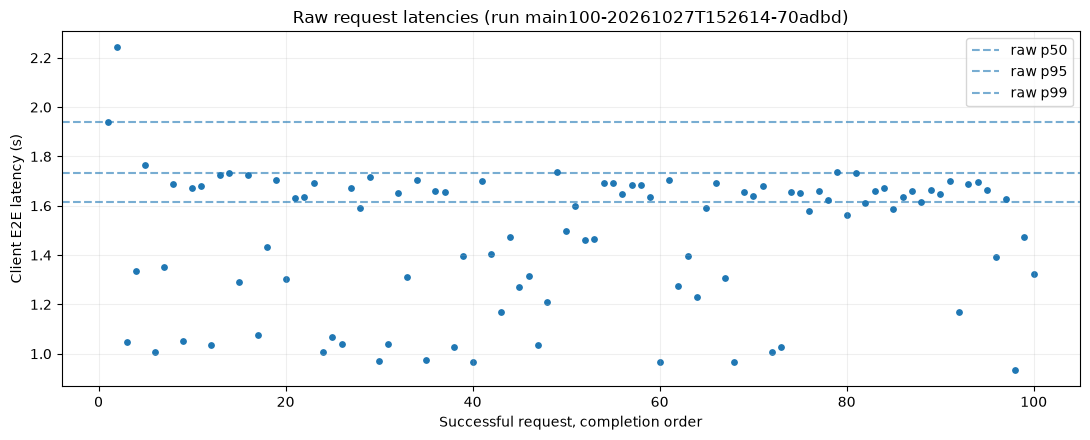

In [11]:
df = RUNS[MAIN_ID]["df"]
vals = df.loc[df.status == "OK", "e2e_s"].to_numpy(float)
if len(vals) >= 2:
    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.scatter(np.arange(1,len(vals)+1), vals, s=15)
    for pct in (50,95,99):
        ax.axhline(np.percentile(vals,pct), linestyle="--", alpha=0.6, label=f"raw p{pct}")
    ax.set(title=f"Raw request latencies (run {MAIN_ID})", xlabel="Successful request, completion order", ylabel="Client E2E latency (s)")
    ax.legend()
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(OUT / f"{MAIN_ID}_latency_chart.png", dpi=150)
    plt.show()

## 12 — Server-side histogram delta (context, **not** estimation error)

This reads the direct vLLM histogram counter snapshots captured before and after the test. When available, the delta isolates server observations for the workload *if no other traffic occurred*. The result might have a different number of observations from the client successes. Both differ in scope and timing, so do **not** report `server_estimate - client_raw` as histogram approximation error. This is useful for inspecting the server instrument and for later server-matched experiments.

In [12]:
def server_delta_report(run_id):
    item=RUNS[run_id]
    before, after = item["before"],item["after"]
    if not before or not after:
        print("No server-side histogram family found for:", SERVER_HISTOGRAM)
        return None
    boundaries = sorted(set(before) | set(after))
    deltas = [after.get(x,0) - before.get(x,0) for x in boundaries]
    if any(d < -1e-9 for d in deltas):
        print("Detected counter reset or inconsistent series; server histogram delta invalid")
        return None
    if boundaries[-1] != math.inf or deltas[-1] <= 0:
        print("Missing valid +Inf bucket or no new server observations")
        return None
    print("Server histogram observations during run:", int(deltas[-1]))
    print("Successful client requests:", int((item["df"].status=="OK").sum()))
    for q in (0.95,0.99):
        print(f"Server histogram p{int(q*100)} estimate: {classic_histogram_quantile(q,boundaries,deltas):.4f} s")
    print("IMPORTANT: server/client time definitions are different; do not interpret gap as estimation error")
    return {"bounds":boundaries,"cumulative":deltas}

MAIN_SERVER = server_delta_report(MAIN_ID)

Server histogram observations during run: 100
Successful client requests: 100
Server histogram p95 estimate: 1.9643 s
Server histogram p99 estimate: 2.0000 s
IMPORTANT: server/client time definitions are different; do not interpret gap as estimation error


## 13 — Optional 500-request replication (OFF by default)

For p99, 500 observations give a stronger (still imperfect) signal. Only enable this after the 100-request run is correct and export files are verified. Keep concurrency and generation settings constant.

In [17]:
RUN_500 = True
if RUN_500:
    LARGE_ID = run_experiment(500, "main500", concurrency=2, batch_size=20)
    LARGE_COMPARISON = compare_run(LARGE_ID)
else:
    print("500-request experiment skipped; set RUN_500=True to opt in.")

main500: finished 20/500 requests
main500: finished 40/500 requests
main500: finished 60/500 requests
main500: finished 80/500 requests
main500: finished 100/500 requests
main500: finished 120/500 requests
main500: finished 140/500 requests
main500: finished 160/500 requests
main500: finished 180/500 requests
main500: finished 200/500 requests
main500: finished 220/500 requests
main500: finished 240/500 requests
main500: finished 260/500 requests
main500: finished 280/500 requests
main500: finished 300/500 requests
main500: finished 320/500 requests
main500: finished 340/500 requests
main500: finished 360/500 requests
main500: finished 380/500 requests
main500: finished 400/500 requests
main500: finished 420/500 requests
main500: finished 440/500 requests
main500: finished 460/500 requests
main500: finished 480/500 requests
main500: finished 500/500 requests
OTLP flush: traces True metrics True
Run ID: main500-20261027T153310-302fd0  | successes: 500 / 500
Saved: /Users/shrutikulkarni/

,layout,quantile,n,raw_s,estimated_s,abs_error_ms,bucket_count,source
0,coarse,p50,500,1.7275,1.5330,194.4053,13,OTLP-exported histogram
1,coarse,p95,500,2.0111,2.1935,182.4902,13,OTLP-exported histogram
2,coarse,p99,500,2.1197,2.8387,718.9811,13,OTLP-exported histogram
3,fine,p50,500,1.7275,1.7058,21.6569,90,OTLP-exported histogram
4,fine,p95,500,2.0111,2.0462,35.1918,90,OTLP-exported histogram
5,fine,p99,500,2.1197,2.1435,23.7630,90,OTLP-exported histogram


## 14 — Optional unsampled vs no-client-tracing overhead probe (OFF by default)

Runs a pair of 30-request benchmarks at the same concurrency with and without SDK spans/histograms. This is a **rough local overhead indicator**, not a definitive causality result: cache, thermal state, and GPU queueing can dominate differences. For better rigor, use repeated ABBA-style ordering and confidence intervals. Files remain under the same local results folder.

In [16]:
RUN_OVERHEAD = True
if RUN_OVERHEAD:
    WITHOUT_ID = run_experiment(30, "without_client_otel", tracing=False, concurrency=2, batch_size=15)
    WITH_ID = run_experiment(30, "with_client_otel", tracing=True, concurrency=2, batch_size=15)
    def overhead_summary(run_id):
        item=RUNS[run_id]
        x=item["df"].loc[item["df"].status=="OK", "e2e_s"].to_numpy(float)
        return {"run":item["label"], "n":len(x),"mean_e2e_s":np.mean(x) if len(x) else math.nan,
                "p95_e2e_s":np.percentile(x,95) if len(x) else math.nan,
                "wall_time_s":item["elapsed_s"]}
    display(pd.DataFrame([overhead_summary(WITHOUT_ID),overhead_summary(WITH_ID)]))
else:
    print("Overhead comparison skipped.")

without_client_otel: finished 15/30 requests
without_client_otel: finished 30/30 requests
Run ID: without_client_otel-20261027T152816-90144e  | successes: 30 / 30
Saved: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/sam_percentile_lab/without_client_otel-20261027T152816-90144e_observations.csv
with_client_otel: finished 15/30 requests
with_client_otel: finished 30/30 requests
OTLP flush: traces True metrics True
Run ID: with_client_otel-20261027T152838-2e4d52  | successes: 30 / 30
Saved: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/sam_percentile_lab/with_client_otel-20261027T152838-2e4d52_observations.csv


,run,n,mean_e2e_s,p95_e2e_s,wall_time_s
0,without_client_otel,30,1.425976,1.723284,22.248406
1,with_client_otel,30,1.638358,1.800545,25.703571


## 15 — Optional vLLM version metrics inventory (no restart)

Sam's first question is independent of percentile accuracy. Save current `# TYPE` declarations, histogram boundaries, and raw metric text **tagged with the running server's version**. Run this section again after you deliberately start a *compatible* different vLLM version. **The Jupyter environment's `import vllm` does not prove the version of the separate server process**: enter the version reported by that server's own `vllm --version` or startup logs.

In [19]:
SERVER_VERSION_LABEL = "0.31.0+cpu"   # Replace with server's actual version, e.g. vllm --version

def snapshot_metric_schema(version_label):
    safe_label = re.sub(r"[^a-zA-Z0-9_.-]", "_", version_label)
    raw = get_url_text(BASE + "/metrics", timeout=12)
    (OUT / f"server_metrics_{safe_label}.prom").write_text(raw)
    metric_types = {}
    for line in raw.splitlines():
        if line.startswith("# TYPE "):
            tokens = line.split(maxsplit=3)
            if len(tokens) >= 4:
                metric_types[tokens[2]]=tokens[3]
    report={"server_version_label":version_label,"metric_types":metric_types,
            "e2e_bucket_bounds":sorted(x for x in server_hist_snapshot() if np.isfinite(x)),
            "saved_at_utc":datetime.now(timezone.utc).isoformat()}
    (OUT / f"schema_{safe_label}.json").write_text(json.dumps(report,indent=2))
    print(f"Saved {len(metric_types)} metric families to schema_{safe_label}.json")
    return report

# Passive snapshot; version label must be filled in manually to enable a trustworthy version comparison.
if SERVER_VERSION_LABEL == "unknown_server_version":
    print("Set SERVER_VERSION_LABEL to the actual SERVING vLLM version before calling snapshot_metric_schema(SERVER_VERSION_LABEL).")
else:
    VERSION_SCHEMA = snapshot_metric_schema(SERVER_VERSION_LABEL)

Saved 82 metric families to schema_0.31.0_cpu.json


In [21]:
print("Total metric families:", len(VERSION_SCHEMA["metric_types"]))

for name, metric_type in sorted(VERSION_SCHEMA["metric_types"].items()):
    print(f"{name:65} {metric_type}")

Total metric families: 82
http_request_duration_highr_seconds                               histogram
http_request_duration_highr_seconds_created                       gauge
http_request_duration_seconds                                     histogram
http_request_duration_seconds_created                             gauge
http_request_size_bytes                                           summary
http_request_size_bytes_created                                   gauge
http_requests_created                                             gauge
http_requests_total                                               counter
http_response_size_bytes                                          summary
http_response_size_bytes_created                                  gauge
python_gc_collections_total                                       counter
python_gc_objects_collected_total                                 counter
python_gc_objects_uncollectable_total                             counter
python_info       

In [22]:
metric_types = VERSION_SCHEMA["metric_types"]

# Exclude automatically generated creation-time metrics
vllm_metrics = {
    name: metric_type
    for name, metric_type in metric_types.items()
    if name.startswith("vllm:")
    and not name.endswith("_created")
}

print("Total exposed metric families:", len(metric_types))
print("vLLM metrics excluding _created:", len(vllm_metrics))

print("\nLatency histograms:")
for name, metric_type in sorted(vllm_metrics.items()):
    if metric_type == "histogram" and (
        "latency" in name or "time" in name
    ):
        print(name)

print("\nE2E histogram bucket boundaries:")
print(VERSION_SCHEMA.get("e2e_bucket_bounds"))

Total exposed metric families: 82
vLLM metrics excluding _created: 37

Latency histograms:
vllm:e2e_request_latency_seconds
vllm:inter_token_latency_seconds
vllm:request_decode_time_seconds
vllm:request_inference_time_seconds
vllm:request_prefill_time_seconds
vllm:request_queue_time_seconds
vllm:request_time_per_output_token_seconds
vllm:time_to_first_token_seconds

E2E histogram bucket boundaries:
[0.3, 0.5, 0.8, 1.0, 1.5, 2.0, 2.5, 5.0, 10.0, 15.0, 20.0, 30.0, 40.0, 50.0, 60.0, 120.0, 240.0, 480.0, 960.0, 1920.0, 7680.0]


## 16 — Produce a concise report for Sam

Populates only measured values. Reports the OTel histogram provenance, counts, limitations, and local artifacts. You can copy the Markdown into a technical note or Slack. This does not claim that full traces are a cost-effective production architecture; that requires the optional overhead and sampling experiments.

In [20]:
selected = MAIN_COMPARISON
successful = RUNS[MAIN_ID]["df"].query("status == 'OK'")
lines = [
    "# Request-level p95/p99 experiment — local vLLM / Qwen3-0.6B",
    f"- Run ID: `{MAIN_ID}`",
    f"- Completed requests: **{len(successful)} / {len(RUNS[MAIN_ID]['df'])}**",
    f"- Concurrency: **{CONCURRENCY}**; max output tokens: **{MAX_TOKENS}**",
    "- Collection: per-request client OTel spans and two client histogram metrics → OTLP/HTTP → Collector → local JSONL",
    "- Reference definition: empirical percentile over successful client E2E values (`numpy.percentile`, linear method)",
    "",
    "| Layout | Percentile | Empirical (s) | Histogram estimate (s) | Absolute error (ms) | Source |",
    "|---|---:|---:|---:|---:|---|",
]
for _,row in selected.iterrows():
    lines.append(f"| {row.layout} | {row['quantile']} | {row.raw_s:.4f} | {row.estimated_s:.4f} | {row.abs_error_ms:.2f} | {row.source} |")
lines += [
    "",
    "**Interpretation:** This is a matched-population histogram estimation test. Client E2E and vLLM server E2E are not interchangeable.",
    "**Limitations:** One Mac M4, one model, short synthetic prompts, limited workload size; raw observations require full-fidelity collection, which may add overhead and storage cost. Six-request pilot is excluded.",
    f"**Artifacts:** `{MAIN_ID}_observations.csv`, `{MAIN_ID}_percentile_comparison.csv`, server histogram snapshots, and the latency PNG.",
]
report_text = "\n".join(lines)
report_file = OUT / f"{MAIN_ID}_report.md"
report_file.write_text(report_text,encoding="utf-8")
display(Markdown(report_text))
print("Saved report:",report_file)

# Request-level p95/p99 experiment — local vLLM / Qwen3-0.6B
- Run ID: `main100-20261027T152614-70adbd`
- Completed requests: **100 / 100**
- Concurrency: **2**; max output tokens: **64**
- Collection: per-request client OTel spans and two client histogram metrics → OTLP/HTTP → Collector → local JSONL
- Reference definition: empirical percentile over successful client E2E values (`numpy.percentile`, linear method)

| Layout | Percentile | Empirical (s) | Histogram estimate (s) | Absolute error (ms) | Source |
|---|---:|---:|---:|---:|---|
| coarse | p50 | 1.6145 | 1.4731 | 141.42 | OTLP-exported histogram |
| coarse | p95 | 1.7336 | 1.9570 | 223.34 | OTLP-exported histogram |
| coarse | p99 | 1.9414 | 2.0000 | 58.65 | OTLP-exported histogram |
| fine | p50 | 1.6145 | 1.5652 | 49.34 | OTLP-exported histogram |
| fine | p95 | 1.7336 | 1.7910 | 57.39 | OTLP-exported histogram |
| fine | p99 | 1.9414 | 1.9685 | 27.11 | OTLP-exported histogram |

**Interpretation:** This is a matched-population histogram estimation test. Client E2E and vLLM server E2E are not interchangeable.
**Limitations:** One Mac M4, one model, short synthetic prompts, limited workload size; raw observations require full-fidelity collection, which may add overhead and storage cost. Six-request pilot is excluded.
**Artifacts:** `main100-20261027T152614-70adbd_observations.csv`, `main100-20261027T152614-70adbd_percentile_comparison.csv`, server histogram snapshots, and the latency PNG.

Saved report: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/sam_percentile_lab/main100-20261027T152614-70adbd_report.md


## 17 — Clean shutdown of **this notebook's OTel SDK only** (opt-in)

Run **after** all trials and the report. The Collector, vLLM, Prometheus and Jupyter services remain running in their own Terminals. Closing the kernel also stops these local providers; use this cell first to flush any pending telemetry.

In [ ]:
SHUTDOWN_NOTEBOOK_OTEL = False
if SHUTDOWN_NOTEBOOK_OTEL:
    LAB_TRACE_PROVIDER.force_flush(timeout_millis=20000)
    LAB_METER_PROVIDER.force_flush(timeout_millis=20000)
    LAB_TRACE_PROVIDER.shutdown()
    LAB_METER_PROVIDER.shutdown()
    print("Notebook OTel SDK stopped. Restart kernel before another experiment.")
else:
    print("SDK still active. No services changed.")

findfont: Failed to find font weight medium for DejaVu Sans, now using 400.


Selected run: main500-20261027T153310-302fd0
Successful requests: 500


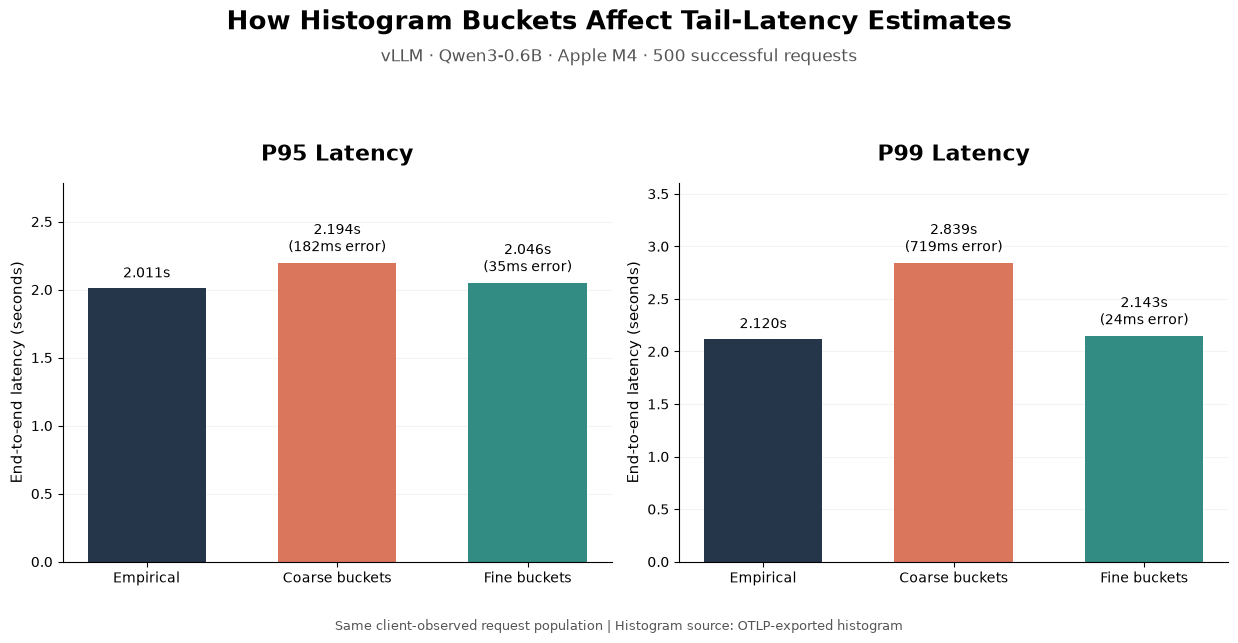


Saved figure: /Users/shrutikulkarni/Pranav-vLLM-Lab/bench_results/sam_percentile_lab/linkedin_vllm_percentile_accuracy.png

Histogram provenance: OTLP-exported histogram


In [23]:

# ============================================================
# LinkedIn Figure — vLLM p95/p99 Histogram Accuracy
# Uses actual results from ParallelIQ OTel Percentiles Lab
# No new inference requests
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

lab_dir = Path(globals().get(
    "OUT", Path.cwd() / "bench_results" / "sam_percentile_lab"
))

# Find completed experiments with both observations and comparisons
candidates = []

for comparison_path in lab_dir.glob("*_percentile_comparison.csv"):
    run_id = comparison_path.name.removesuffix(
        "_percentile_comparison.csv"
    )
    observations_path = lab_dir / f"{run_id}_observations.csv"

    if not observations_path.exists():
        continue

    observations = pd.read_csv(observations_path)
    comparison = pd.read_csv(comparison_path)

    valid = observations[
        (observations["status"] == "OK") &
        np.isfinite(observations["e2e_s"])
    ]

    if len(valid) >= 20:
        candidates.append(
            (len(valid), run_id, valid, comparison)
        )

if not candidates:
    raise FileNotFoundError(
        "No completed comparison found. Run compare_run(MAIN_ID) "
        "or compare_run(LARGE_ID) first."
    )

# Prefer the experiment with the largest successful request population
n, run_id, observations, comparison = max(
    candidates, key=lambda x: x[0]
)

print(f"Selected run: {run_id}")
print(f"Successful requests: {n}")

# Calculate empirical percentiles from the actual observations
values = observations["e2e_s"].to_numpy(dtype=float)

percentiles = ["p95", "p99"]
results = {}

for percentile in percentiles:
    q = int(percentile[1:])
    empirical = float(np.percentile(values, q, method="linear"))

    rows = comparison[
        comparison["quantile"] == percentile
    ]

    estimates = {}

    for layout in ["coarse", "fine"]:
        matching = rows[rows["layout"] == layout]

        if len(matching) != 1:
            raise ValueError(
                f"Missing or duplicate {layout} {percentile} result"
            )

        record = matching.iloc[0]

        if not np.isclose(
            float(record["raw_s"]), empirical, atol=1e-6
        ):
            raise ValueError(
                "Comparison CSV doesn't match raw observations"
            )

        if int(record["n"]) != n:
            raise ValueError("Request counts don't match")

        estimates[layout] = float(record["estimated_s"])

    results[percentile] = {
        "Empirical": empirical,
        "Coarse buckets": estimates["coarse"],
        "Fine buckets": estimates["fine"],
    }

# ------------------------------------------------------------
# Plot — research-style comparison
# ------------------------------------------------------------

colors = ["#26364A", "#DA765B", "#338C83"]
labels = ["Empirical", "Coarse buckets", "Fine buckets"]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
fig.patch.set_facecolor("white")

for ax, percentile in zip(axes, percentiles):
    data = results[percentile]
    heights = [data[label] for label in labels]
    empirical = data["Empirical"]

    bars = ax.bar(
        labels, heights, color=colors, width=0.62
    )

    for i, (bar, value) in enumerate(zip(bars, heights)):
        annotation = f"{value:.3f}s"

        if i != 0:
            error_ms = abs(value - empirical) * 1000
            annotation += f"\n({error_ms:.0f}ms error)"

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value + max(heights) * 0.025,
            annotation,
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="medium",
        )

    ax.set_title(
        f"{percentile.upper()} Latency",
        fontsize=16,
        fontweight="bold",
        pad=16,
    )

    ax.set_ylabel("End-to-end latency (seconds)", fontsize=11)
    ax.set_ylim(0, max(heights) * 1.27)
    ax.tick_params(axis="x", labelsize=10)
    ax.tick_params(axis="y", labelsize=10)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)

    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.suptitle(
    "How Histogram Buckets Affect Tail-Latency Estimates",
    fontsize=19,
    fontweight="bold",
    y=0.99,
)

fig.text(
    0.5, 0.91,
    f"vLLM · Qwen3-0.6B · Apple M4 · {n} successful requests",
    ha="center",
    fontsize=12,
    color="#555555",
)

sources = sorted(
    comparison[
        comparison["quantile"].isin(percentiles)
    ]["source"].dropna().unique()
)

source_label = "; ".join(sources)

fig.text(
    0.5, 0.035,
    "Same client-observed request population | "
    f"Histogram source: {source_label}",
    ha="center",
    fontsize=9,
    color="#555555",
)

fig.tight_layout(rect=[0.02, 0.08, 0.98, 0.87])

# Export for LinkedIn
output = lab_dir / "linkedin_vllm_percentile_accuracy.png"

fig.savefig(
    output,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print(f"\nSaved figure: {output}")
print("\nHistogram provenance:", source_label)

if any("fallback" in s.lower() for s in sources):
    print(
        "WARNING: Histogram values were reconstructed. "
        "Do not describe them as verified OTLP exports."
    )
